# CSC61304 – Machine Learning and Intelligent Systems (Sep 2026)
## Individual Assignment: Predicting Top-10 Finishes in PUBG Mobile Matches (simulated 10,000-row dataset)

**Student ID:** `XXXXXX`  |  **Lecture Group:** `XX`

This notebook follows the report structure of the assignment brief (Parts 1–10).

**Dataset disclosure:** `PUBG_Mobile_Top10_Synthetic_10000.csv` is a **simulated** dataset of 10,000 independent players, generated with documented assumptions (a hidden "skill" variable drives survival time, kills, damage and placement, plus random noise). It is **not** real match telemetry. Scores therefore show how well the ML pipeline recovers the relationships built into the simulation, not how predictable real PUBG Mobile players are. Part 3 verifies that the rows are independent (no duplicated or near-duplicated records), so a normal split is valid; the group-aware code is kept as a safety net (each row is its own group).

In [1]:
# ---------- Setup ----------
import os, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import FancyBboxPatch

from sklearn.model_selection import (GroupShuffleSplit, GroupKFold, RandomizedSearchCV,
                                     train_test_split, cross_val_score)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.neighbors import NearestNeighbors
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, balanced_accuracy_score, accuracy_score,
                             roc_curve, precision_recall_curve, confusion_matrix,
                             ConfusionMatrixDisplay, brier_score_loss)

warnings.filterwarnings("ignore")
SEED = 9
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
os.makedirs("figures", exist_ok=True)

# Dataset location: works locally, on Google Colab, or in the upload folder
CANDIDATES = ["PUBG_Mobile_Top10_Synthetic_10000.csv",
              "/content/PUBG_Mobile_Top10_Synthetic_10000.csv",
              "/mnt/user-data/uploads/PUBG_Mobile_Top10_Synthetic_10000.csv"]
DATA_PATH = next((p for p in CANDIDATES if os.path.exists(p)), None)
assert DATA_PATH, "Dataset not found – upload the CSV next to this notebook."
print("Using:", DATA_PATH)

Using: PUBG_Mobile_Top10_Synthetic_10000.csv


# Part 1 – Introduction and Problem Definition

**Domain:** Mobile esports in Nepal / South Asia.
**Problem:** Predict whether a player finishes a match in the **Top 10** (`Match_Rank <= 10`) from the player's in-match statistics and profile (map, tier, weapon, combat and survival statistics).

**Why this matters (write up in your report with citations):**
- *Background:* PUBG Mobile is one of the most played mobile games in Nepal and has a large competitive scene (e.g. national tournaments and university/college leagues). Teams and coaches need data-driven ways to understand what drives placement.
- *Local scenario:* Nepali teams have limited analytics tooling and coaching budgets; the system would give affordable, data-based feedback.
- *Global scenario:* Esports analytics (performance prediction, player scouting, matchmaking) is a growing field.
- *Stakeholders:* players, coaches/team managers, tournament organisers, game-community platforms.

**Aim:** Build and critically evaluate an ML system that predicts Top-10 placement.

**Objectives**
1. Explore and clean the PUBG Mobile dataset and identify data-quality risks.
2. Engineer features and train at least two comparative models (Logistic Regression, Random Forest).
3. Tune hyper-parameters with leakage-safe cross-validation.
4. Evaluate with metrics suited to an imbalanced target and interpret the results honestly.
5. Propose an intelligent-system architecture and an ethical governance plan.

> Add 10+ references (APA 7 / IEEE) and at least 5 recent papers in the Literature Review of your report. Suggested search terms: *esports analytics*, *PUBG match outcome prediction*, *battle royale player performance machine learning*, *class imbalance evaluation precision-recall*, *data leakage in machine learning*.

# Part 2 – Data Source, Dataset Table and Pipeline

### 2.1 Data source and generation assumptions (complete for the report)
* **Source:** self-generated simulated dataset (`PUBG_Mobile_Top10_Synthetic_10000.csv`), created with the help of an AI tool *(cite the tool and add prompt screenshots to the Appendix)*.
* **Why simulated:** no public PUBG Mobile / Nepal match-log dataset with this schema was available; the lecturer approved a synthetic dataset *(add date/evidence)*.
* **Assumed relationships:** a hidden player-skill variable raises survival time, kills and damage; longer survival and more kills improve placement; heals/boosts rise with survival time; placement includes substantial random noise.
* **What this means:** scores reflect how well the pipeline learns the assumed rules, not real-player predictability.

In [2]:
df_raw = pd.read_csv(DATA_PATH)
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (10000, 16)


,Player_ID,Map,Tier,Kills,Damage_Dealt,Survival_Time_Minutes,Headshot_Percentage,Assists,Revives,Distance_Travelled_km,Longest_Kill_meters,Heals_Used,Boosts_Used,Match_Rank,Win,Favorite_Weapon
0,PUBG_00001,Miramar,Diamond,3,272.13,20.22,57.51,4,5,3.76,42.50,8,2,52,0,UMP45
1,PUBG_00002,Livik,Platinum,2,25.38,9.50,41.16,4,1,0.58,25.37,3,2,66,0,M416
2,PUBG_00003,Erangel,Platinum,6,650.80,26.94,52.73,7,1,2.32,77.55,6,3,1,1,M416
3,PUBG_00004,Vikendi,Crown,5,506.64,27.00,55.46,9,2,3.34,241.66,6,5,20,0,M416
4,PUBG_00005,Livik,Silver,0,61.11,7.95,25.89,1,1,1.47,33.83,3,1,81,0,AKM


In [3]:
# Dataset description table (copy into the report)
desc = pd.DataFrame({
    "Column": df_raw.columns,
    "Type": df_raw.dtypes.astype(str).values,
    "Non-null": df_raw.notna().sum().values,
    "Unique": df_raw.nunique().values,
    "Example": [df_raw[c].iloc[0] for c in df_raw.columns],
})
meaning = {
    "Player_ID": "Unique row identifier (PUBG_##### (simulated player))",
    "Map": "Map played (Erangel, Miramar, Sanhok, Vikendi, Livik)",
    "Tier": "Player rank tier (Bronze … Conqueror)",
    "Kills": "Eliminations in the match",
    "Damage_Dealt": "Total damage dealt",
    "Survival_Time_Minutes": "Minutes survived (5–30)",
    "Headshot_Percentage": "Share of kills that were headshots (%)",
    "Assists": "Assisted eliminations",
    "Revives": "Teammates revived",
    "Distance_Travelled_km": "Distance travelled (km)",
    "Longest_Kill_meters": "Longest kill distance (m)",
    "Heals_Used": "Healing items used",
    "Boosts_Used": "Boost items used",
    "Match_Rank": "Final placement (1 = best, 100 = worst)",
    "Win": "1 if the player won the match",
    "Favorite_Weapon": "Preferred weapon",
    "Record_Type": "Original or Synthetic record",
}
desc["Description"] = desc["Column"].map(meaning)
desc

,Column,Type,Non-null,Unique,Example,Description
0,Player_ID,str,10000,10000,PUBG_00001,Unique row identifier (PUBG_##### (simulated p...
1,Map,str,10000,5,Miramar,"Map played (Erangel, Miramar, Sanhok, Vikendi,..."
2,Tier,str,10000,8,Diamond,Player rank tier (Bronze … Conqueror)
3,Kills,int64,10000,16,3,Eliminations in the match
4,Damage_Dealt,float64,10000,8765,272.13,Total damage dealt
5,Survival_Time_Minutes,float64,10000,2185,20.22,Minutes survived (5–30)
6,Headshot_Percentage,float64,10000,3104,57.51,Share of kills that were headshots (%)
7,Assists,int64,10000,16,4,Assisted eliminations
8,Revives,int64,10000,9,5,Teammates revived
9,Distance_Travelled_km,float64,10000,516,3.76,Distance travelled (km)


In [4]:
print("Missing values:", int(df_raw.isna().sum().sum()))
print("Duplicate rows (excluding ID):", int(df_raw.drop(columns="Player_ID").duplicated().sum()))
print("Unique Player_IDs:", df_raw.Player_ID.nunique(), "| example IDs:", df_raw.Player_ID.head(3).tolist())
print("(Simulated dataset - see the disclosure at the top of this notebook.)\n")
df_raw.describe().T.round(2)

Missing values: 0
Duplicate rows (excluding ID): 0
Unique Player_IDs: 10000 | example IDs: ['PUBG_00001', 'PUBG_00002', 'PUBG_00003']
(Simulated dataset - see the disclosure at the top of this notebook.)



,count,mean,std,min,25%,50%,75%,max
Kills,10000.0,2.88,2.10,0.00,1.00,3.00,4.00,15.00
Damage_Dealt,10000.0,288.26,183.24,0.00,150.70,271.97,402.86,1256.58
Survival_Time_Minutes,10000.0,18.32,5.23,5.00,14.75,18.30,21.88,30.00
Headshot_Percentage,10000.0,44.02,8.33,11.14,39.03,45.46,50.38,59.16
Assists,10000.0,3.45,2.09,0.00,2.00,3.00,5.00,15.00
Revives,10000.0,1.58,1.34,0.00,1.00,1.00,2.00,8.00
Distance_Travelled_km,10000.0,2.69,0.93,0.20,2.06,2.69,3.33,6.30
Longest_Kill_meters,10000.0,100.31,77.31,6.92,49.74,79.41,126.14,1500.00
Heals_Used,10000.0,5.14,2.66,0.00,3.00,5.00,7.00,17.00
Boosts_Used,10000.0,3.20,1.98,0.00,2.00,3.00,4.00,13.00


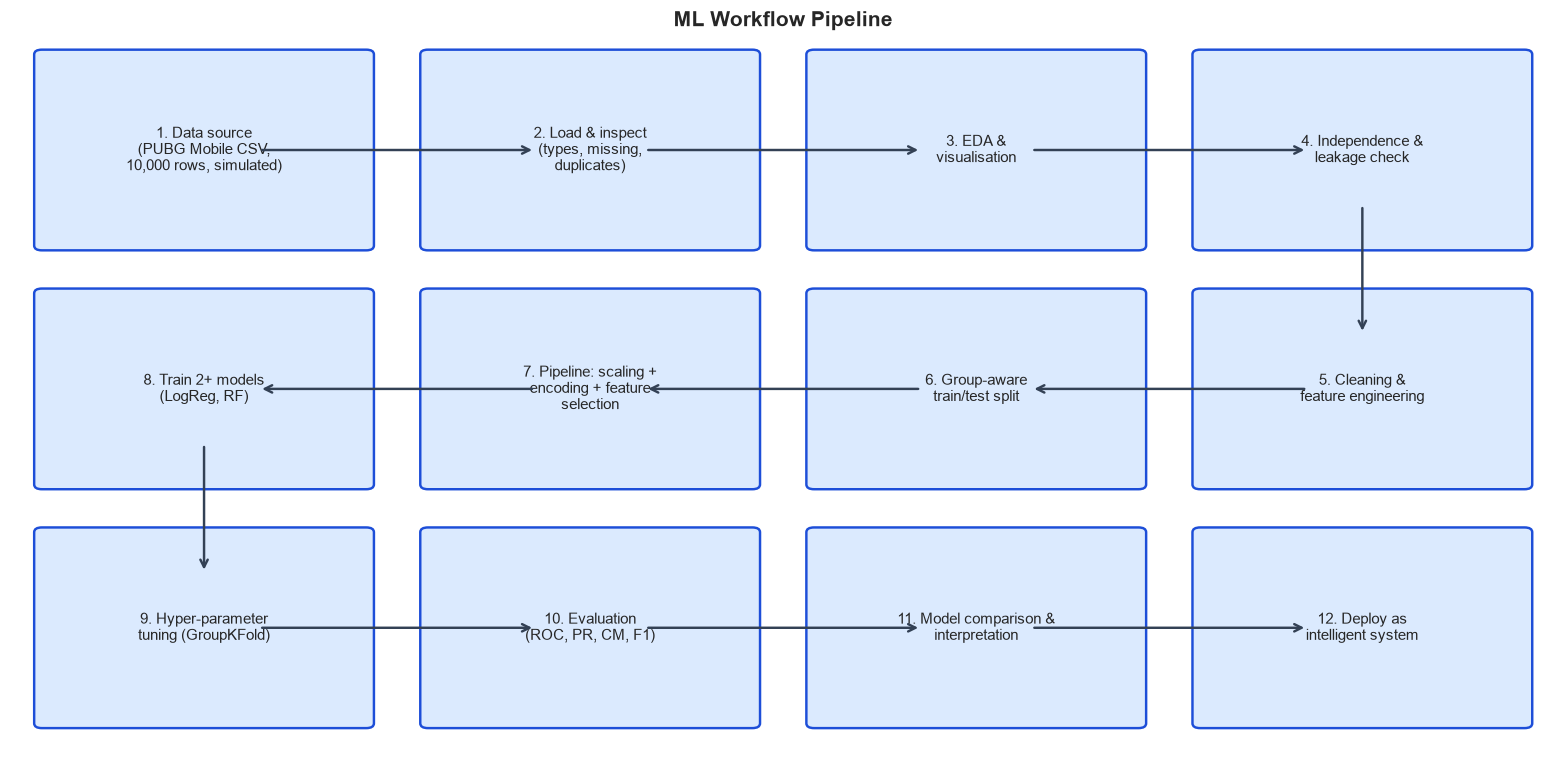

In [5]:
# ---------- Workflow pipeline diagram (Section 3 of the report) ----------
def draw_flow(steps, title, fname, ncols=4, color="#dbeafe", edge="#1d4ed8"):
    nrows = int(np.ceil(len(steps) / ncols))
    fig, ax = plt.subplots(figsize=(3.6 * ncols, 2.1 * nrows + 0.8))
    ax.set_xlim(0, ncols); ax.set_ylim(0, nrows); ax.axis("off")
    ax.set_title(title, fontsize=14, fontweight="bold")
    pos = []
    for i, s in enumerate(steps):
        r, c = divmod(i, ncols)
        if r % 2 == 1:            # snake layout
            c = ncols - 1 - c
        x, y = c + 0.08, nrows - r - 0.88
        pos.append((x + 0.42, y + 0.4))
        ax.add_patch(FancyBboxPatch((x, y), 0.84, 0.8, boxstyle="round,pad=0.02",
                                    fc=color, ec=edge, lw=1.6))
        ax.text(x + 0.42, y + 0.4, f"{i+1}. {s}", ha="center", va="center", fontsize=9.5, wrap=True)
    for a, b in zip(pos[:-1], pos[1:]):
        ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="->", lw=1.6, color="#334155",
                                                        shrinkA=38, shrinkB=38))
    plt.tight_layout(); plt.savefig(fname, bbox_inches="tight"); plt.show()

draw_flow(["Data source\n(PUBG Mobile CSV,\n10,000 rows, simulated)", "Load & inspect\n(types, missing,\nduplicates)",
           "EDA &\nvisualisation", "Independence &\nleakage check",
           "Cleaning &\nfeature engineering", "Group-aware\ntrain/test split",
           "Pipeline: scaling +\nencoding + feature\nselection", "Train 2+ models\n(LogReg, RF)",
           "Hyper-parameter\ntuning (GroupKFold)", "Evaluation\n(ROC, PR, CM, F1)",
           "Model comparison &\ninterpretation", "Deploy as\nintelligent system"],
          "ML Workflow Pipeline", "figures/workflow_pipeline.png")

# Part 3 – Exploratory Data Analysis (EDA)

In [6]:
df = df_raw.copy()
df["Top10"] = (df["Match_Rank"] <= 10).astype(int)
num_cols = ["Kills", "Damage_Dealt", "Survival_Time_Minutes", "Headshot_Percentage", "Assists",
            "Revives", "Distance_Travelled_km", "Longest_Kill_meters", "Heals_Used", "Boosts_Used"]
cat_cols = ["Map", "Tier", "Favorite_Weapon"]

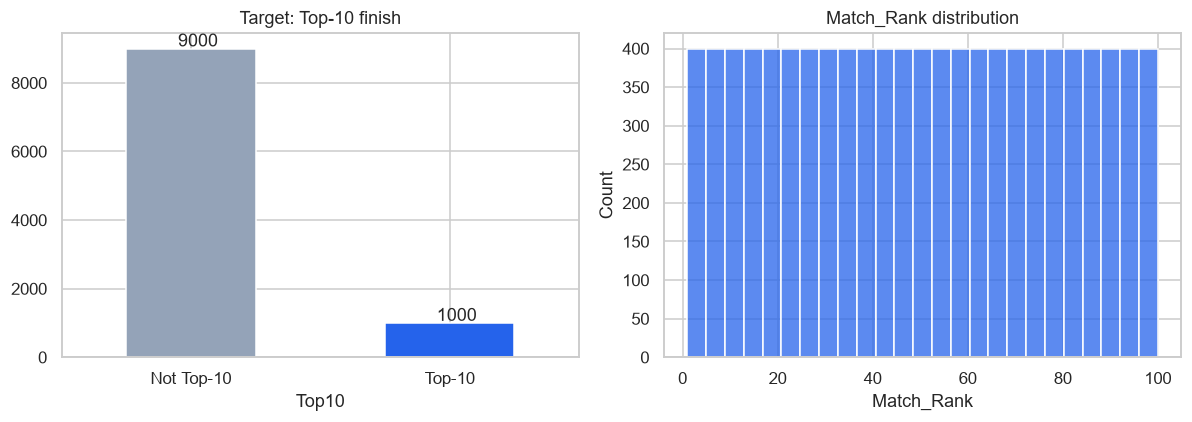

Top-10 rate: 10.00% | Win rate: 1.00%


In [7]:
# 3.1 Target distribution – the problem is imbalanced
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df["Top10"].value_counts().sort_index().plot(kind="bar", ax=ax[0], color=["#94a3b8", "#2563eb"])
ax[0].set_xticklabels(["Not Top-10", "Top-10"], rotation=0); ax[0].set_title("Target: Top-10 finish")
for p in ax[0].patches:
    ax[0].annotate(f"{int(p.get_height())}", (p.get_x()+0.2, p.get_height()+60))
sns.histplot(df["Match_Rank"], bins=25, ax=ax[1], color="#2563eb"); ax[1].set_title("Match_Rank distribution")
plt.tight_layout(); plt.savefig("figures/eda_target.png"); plt.show()
print(f"Top-10 rate: {df.Top10.mean():.2%} | Win rate: {df.Win.mean():.2%}")

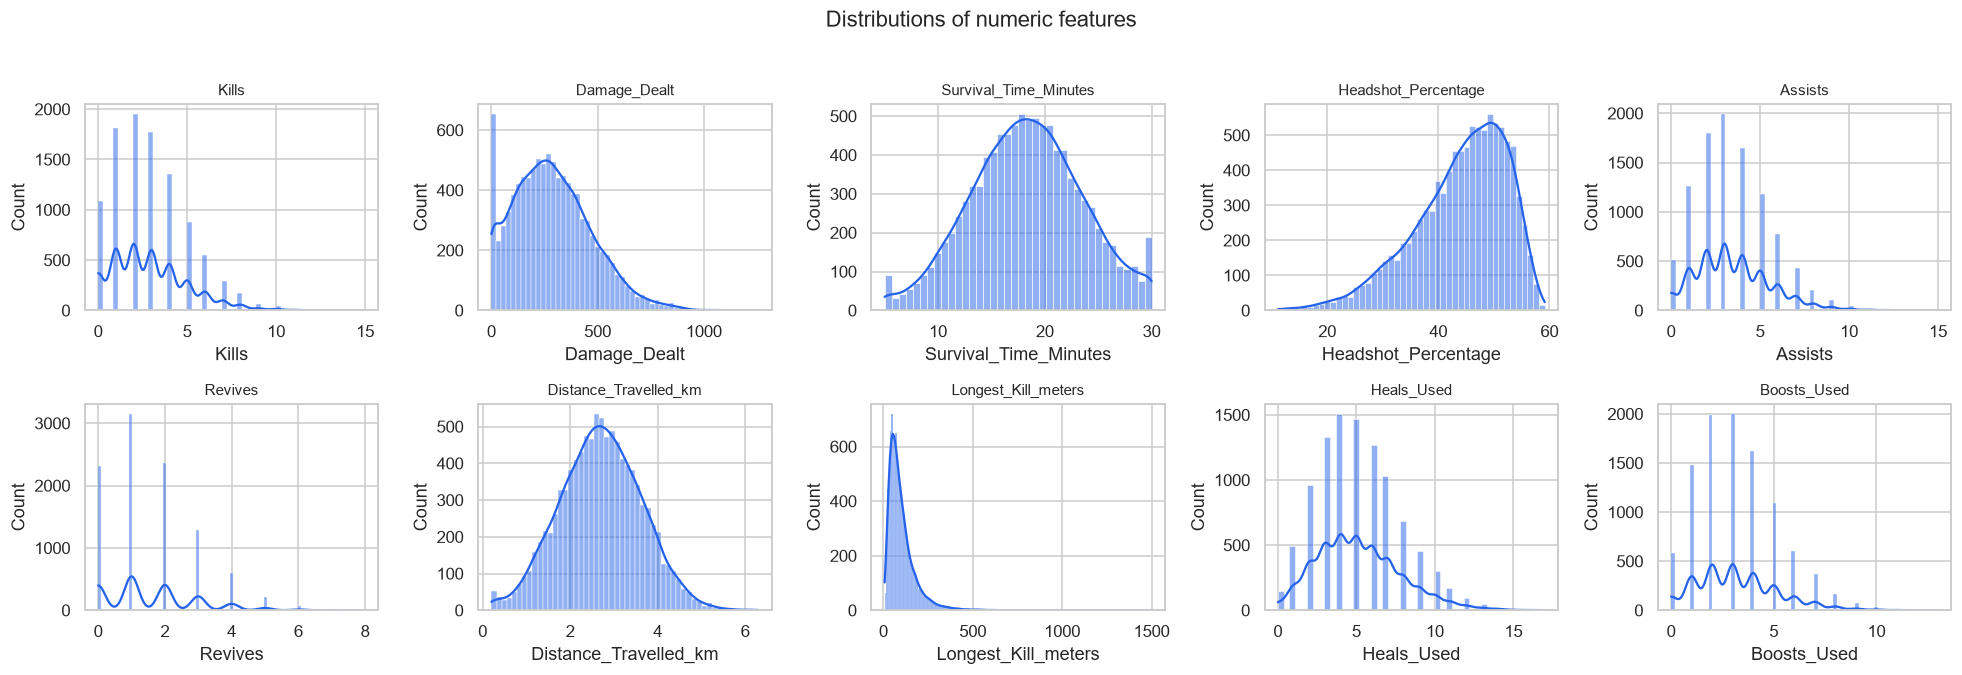

In [8]:
# 3.2 Numeric distributions
fig, axes = plt.subplots(2, 5, figsize=(18, 6))
for a, c in zip(axes.ravel(), num_cols):
    sns.histplot(df[c], kde=True, ax=a, color="#2563eb"); a.set_title(c, fontsize=10)
plt.suptitle("Distributions of numeric features", y=1.02); plt.tight_layout()
plt.savefig("figures/eda_distributions.png", bbox_inches="tight"); plt.show()

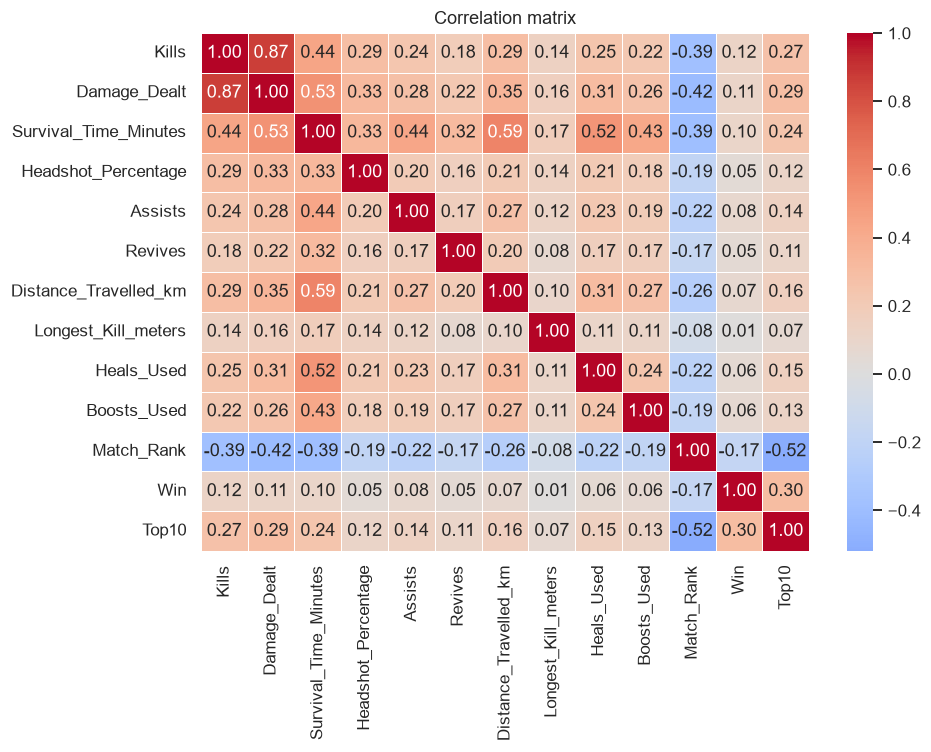

Strongest feature–target correlation: 0.289


In [9]:
# 3.3 Correlation heat-map
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols + ["Match_Rank", "Win", "Top10"]].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, linewidths=.4)
plt.title("Correlation matrix"); plt.tight_layout(); plt.savefig("figures/eda_corr.png"); plt.show()
corr_t = df[num_cols].corrwith(df["Top10"]).sort_values()
print("Strongest feature–target correlation:", round(corr_t.abs().max(), 3))

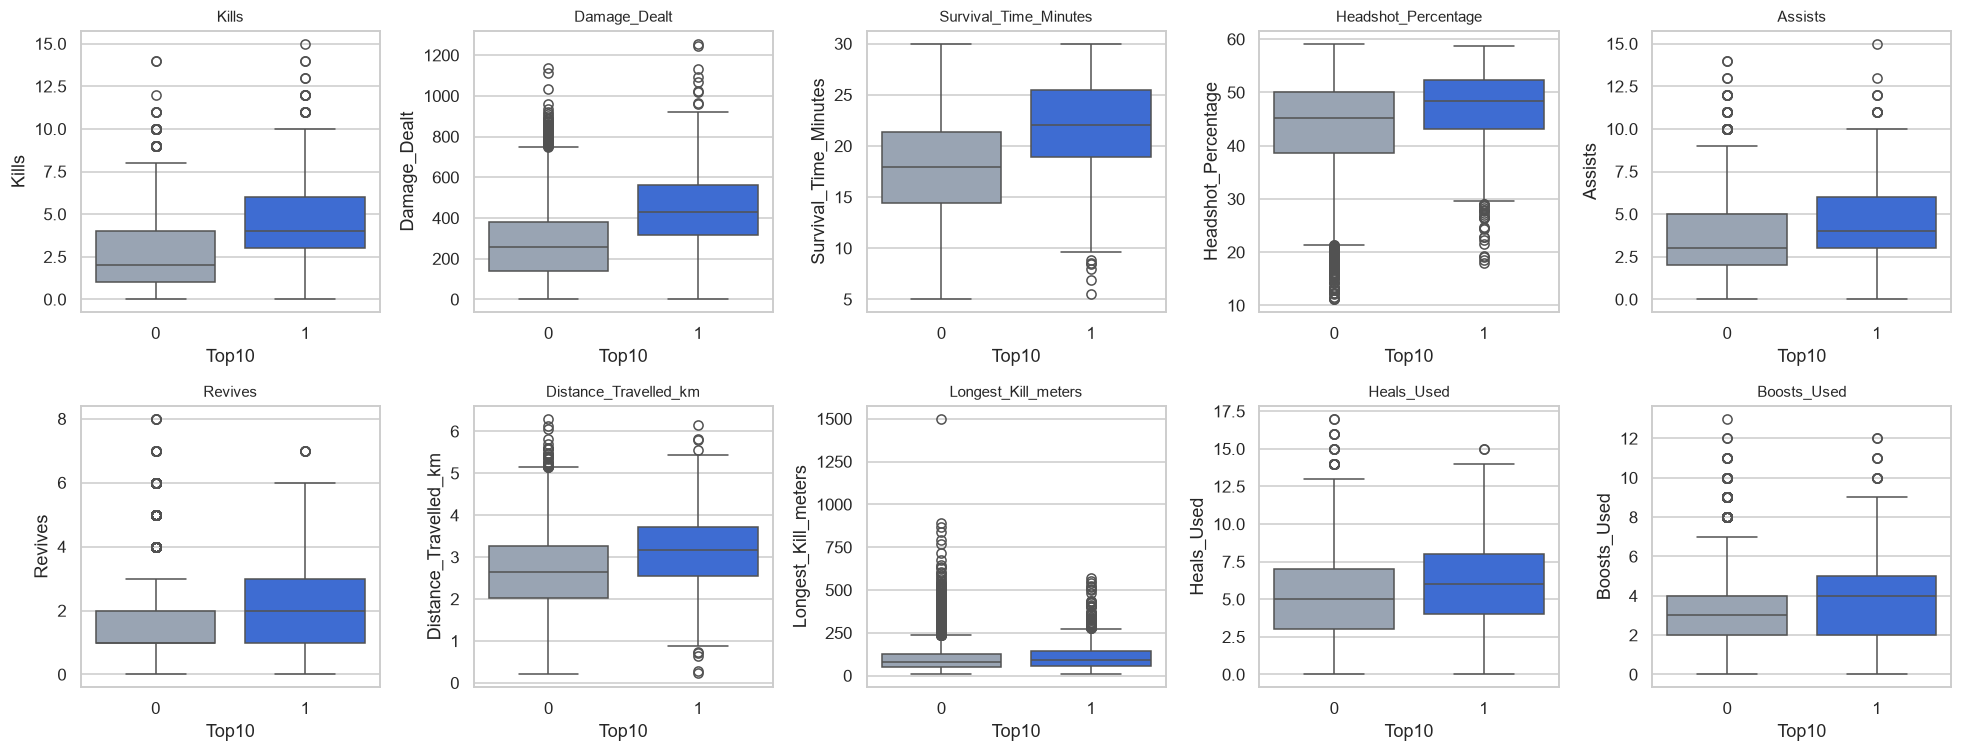

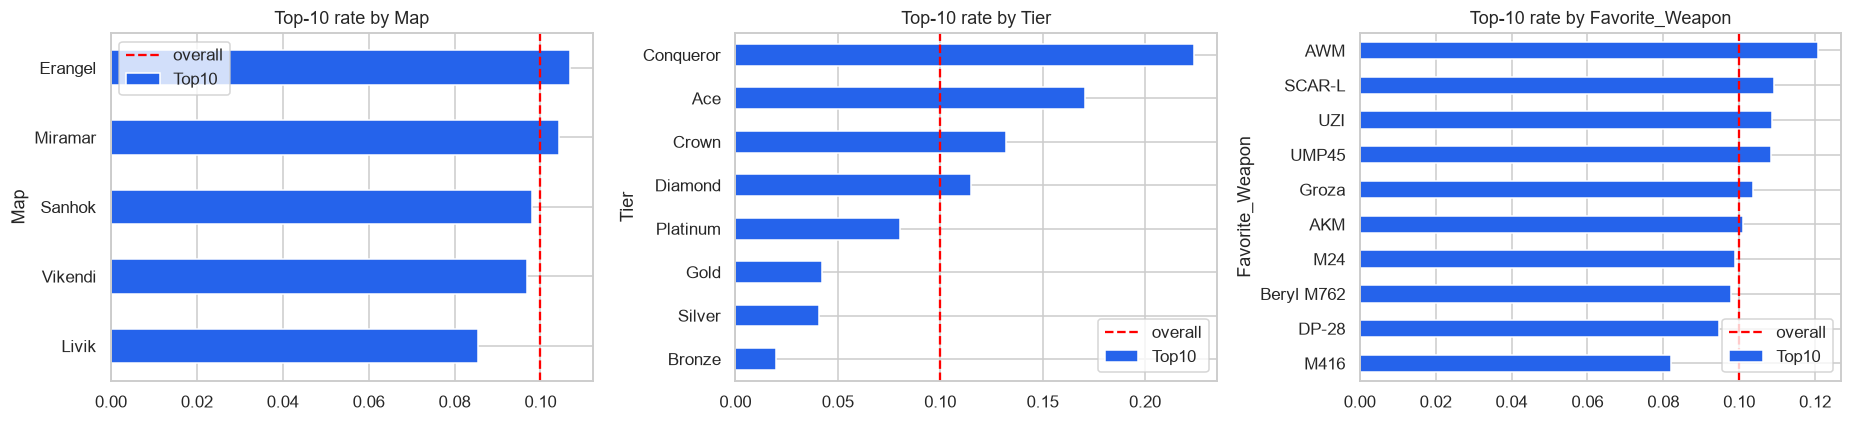

In [10]:
# 3.4 Feature vs target (box-plots) and categorical Top-10 rates
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for a, c in zip(axes.ravel(), num_cols):
    sns.boxplot(x="Top10", y=c, data=df, ax=a, palette=["#94a3b8", "#2563eb"]); a.set_title(c, fontsize=10)
plt.tight_layout(); plt.savefig("figures/eda_box.png"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for a, c in zip(axes, cat_cols):
    df.groupby(c)["Top10"].mean().sort_values().plot(kind="barh", ax=a, color="#2563eb")
    a.axvline(df.Top10.mean(), color="red", ls="--", label="overall"); a.set_title(f"Top-10 rate by {c}"); a.legend()
plt.tight_layout(); plt.savefig("figures/eda_cat.png"); plt.show()

In [11]:
# 3.5 Outliers (IQR rule)
rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    rows.append((c, int(((df[c] < q1 - 1.5*iqr) | (df[c] > q3 + 1.5*iqr)).sum())))
print(pd.DataFrame(rows, columns=["Feature", "IQR outliers"]).to_string(index=False))
print("\nRows with Damage_Dealt == 0 but Kills > 0 (logically suspicious):",
      int(((df.Damage_Dealt == 0) & (df.Kills > 0)).sum()))

              Feature  IQR outliers
                Kills           131
         Damage_Dealt           109
Survival_Time_Minutes             0
  Headshot_Percentage           152
              Assists            84
              Revives           904
Distance_Travelled_km            28
  Longest_Kill_meters           532
           Heals_Used            41
          Boosts_Used           283

Rows with Damage_Dealt == 0 but Kills > 0 (logically suspicious): 146


### 3.6 Independence and leakage check
A simulated dataset is only valid for a normal train/test split if its rows are independent. We check that (a) there are no duplicated or near-duplicated rows, (b) no single feature trivially encodes the target, and then give every row its own group so the group-aware code in later parts still works.

Distance to nearest other row (standardised): min 0.276 | 1st pct 0.609 | median 1.124
Rows with a near-duplicate (distance < 0.10): 0 of 10000

Best single-feature ROC-AUC for Top-10 (should be far below 0.95):
Damage_Dealt             0.754
Kills                    0.734
Survival_Time_Minutes    0.727
Distance_Travelled_km    0.651
Heals_Used               0.642
Assists                  0.628
Headshot_Percentage      0.615
Boosts_Used              0.615
Revives                  0.597
Longest_Kill_meters      0.569


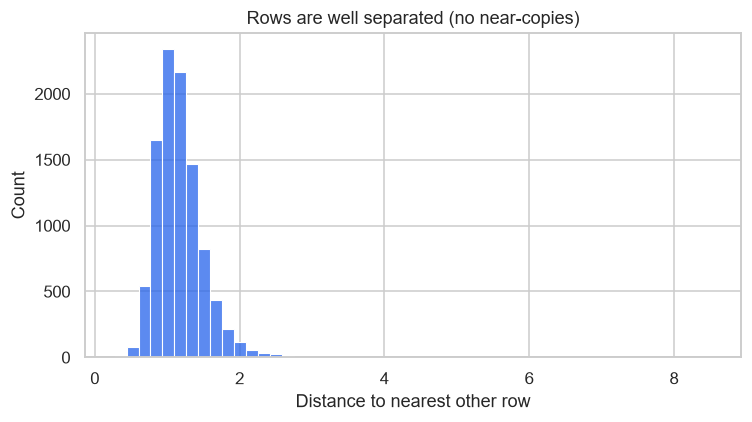

In [12]:
mu, sd = df[num_cols].mean(), df[num_cols].std()
Zall = ((df[num_cols] - mu) / sd).values
dist, idx = NearestNeighbors(n_neighbors=2).fit(Zall).kneighbors(Zall)
d1 = dist[:, 1]
print("Distance to nearest other row (standardised): "
      f"min {d1.min():.3f} | 1st pct {np.percentile(d1,1):.3f} | median {np.median(d1):.3f}")
print("Rows with a near-duplicate (distance < 0.10):", int((d1 < 0.10).sum()), "of", len(df))

# no single feature should (almost) perfectly predict the target
single = {c: roc_auc_score(df["Top10"], df[c]) for c in num_cols}
single = pd.Series({c: max(a, 1 - a) for c, a in single.items()}).sort_values(ascending=False)
print("\nBest single-feature ROC-AUC for Top-10 (should be far below 0.95):")
print(single.round(3).to_string())

df["Group"] = np.arange(len(df))        # every row is independent -> its own group

plt.figure(figsize=(7, 4))
sns.histplot(d1, bins=50, color="#2563eb"); plt.xlabel("Distance to nearest other row")
plt.title("Rows are well separated (no near-copies)"); plt.tight_layout()
plt.savefig("figures/eda_leakage.png"); plt.show()

**EDA insights (interpret in your report using the numbers above):**
* Top-10 finishes are about 10 % of players and wins about 1 %, so the target is imbalanced and plain accuracy is misleading (always predicting "No" gives ~90 %).
* Unlike the earlier expanded file, features now show clear positive correlations with Top-10 (damage, kills, survival time strongest) and negative correlations with `Match_Rank`. This is by design of the simulation.
* No near-duplicate rows were found and no single feature predicts the target almost perfectly, so a standard split is not leaky.
* Because the data are simulated, say clearly in the report which relationships were assumed (e.g. skill → survival time → placement).

# Part 4 – Data Preprocessing

In [13]:
# 4.1 Cleaning
data = df.copy()
before = len(data)
data = data.drop_duplicates(subset=[c for c in data.columns if c != "Player_ID"])
for c, (lo, hi) in {"Headshot_Percentage": (0, 100), "Survival_Time_Minutes": (0, 40),
                    "Match_Rank": (1, 100)}.items():
    assert data[c].between(lo, hi).all(), f"{c} out of range"
print(f"Rows before/after de-duplication: {before} -> {len(data)}; missing values: {int(data.isna().sum().sum())}")
# Outliers are plausible gameplay values (bounded ranges), so they are kept rather than removed.
# Whole-number counts stored as floats are cast to integers.
for c in ["Kills", "Assists", "Revives", "Heals_Used", "Boosts_Used"]:
    data[c] = data[c].round().astype(int)

Rows before/after de-duplication: 10000 -> 10000; missing values: 0


In [14]:
# 4.2 Feature engineering (row-wise only - no information is shared across rows, so no leakage)
# Wrapped in a function so the SAME code is reused by the deployed advise() function.
eps = 1e-6
TIER_ORDER = ["Bronze", "Silver", "Gold", "Platinum", "Diamond", "Crown", "Ace", "Master", "Grandmaster", "Conqueror"]
tier_rank = {t: i for i, t in enumerate(TIER_ORDER)}
print("Tiers in data:", sorted(data["Tier"].unique()))

def add_features(d):
    d = d.copy()
    d["Kills_per_Min"] = d["Kills"] / (d["Survival_Time_Minutes"] + eps)
    d["Damage_per_Min"] = d["Damage_Dealt"] / (d["Survival_Time_Minutes"] + eps)
    d["Damage_per_Kill"] = d["Damage_Dealt"] / (d["Kills"] + 1)
    d["Distance_per_Min"] = d["Distance_Travelled_km"] / (d["Survival_Time_Minutes"] + eps)
    d["Consumables_Total"] = d["Heals_Used"] + d["Boosts_Used"]
    d["Support_Score"] = d["Assists"] + d["Revives"]
    d["Headshot_Kills"] = d["Kills"] * d["Headshot_Percentage"] / 100
    d["Long_Range_Flag"] = (d["Longest_Kill_meters"] > 250).astype(int)
    d["Kills_x_Survival"] = d["Kills"] * d["Survival_Time_Minutes"]          
    d["Damage_x_Headshot"] = d["Damage_Dealt"] * d["Headshot_Percentage"] / 100
    d["Heal_per_Min"] = d["Consumables_Total"] / (d["Survival_Time_Minutes"] + eps)
    d["Survival_Share"] = d["Survival_Time_Minutes"] / 30.0                   
    d["Tier_Ord"] = d["Tier"].map(tier_rank)                                 
    return d

data = add_features(data)
if data["Tier_Ord"].isna().any():          # tier names not in TIER_ORDER -> fall back to the median rank
    print("WARNING: unmapped tiers:", data.loc[data.Tier_Ord.isna(), "Tier"].unique(), "-> filled with median")
    data["Tier_Ord"] = data["Tier_Ord"].fillna(data["Tier_Ord"].median())
eng_cols = ["Kills_per_Min", "Damage_per_Min", "Damage_per_Kill", "Distance_per_Min", "Consumables_Total",
            "Support_Score", "Headshot_Kills", "Long_Range_Flag",
            "Kills_x_Survival", "Damage_x_Headshot", "Heal_per_Min", "Survival_Share", "Tier_Ord"]
data[eng_cols].describe().T.round(2)


Tiers in data: ['Ace', 'Bronze', 'Conqueror', 'Crown', 'Diamond', 'Gold', 'Platinum', 'Silver']


,count,mean,std,min,25%,50%,75%,max
Kills_per_Min,10000.0,0.16,0.11,0.00,0.08,0.14,0.22,0.85
Damage_per_Min,10000.0,15.48,9.20,0.00,9.19,14.90,20.95,77.29
Damage_per_Kill,10000.0,73.20,35.90,0.00,55.06,73.74,90.55,419.20
Distance_per_Min,10000.0,0.15,0.05,0.01,0.12,0.15,0.18,0.63
Consumables_Total,10000.0,8.34,3.68,0.00,6.00,8.00,11.00,23.00
Support_Score,10000.0,5.03,2.66,0.00,3.00,5.00,7.00,18.00
Headshot_Kills,10000.0,1.32,1.05,0.00,0.48,1.07,1.92,7.67
Long_Range_Flag,10000.0,0.05,0.21,0.00,0.00,0.00,0.00,1.00
Kills_x_Survival,10000.0,57.66,50.67,0.00,19.05,45.17,82.95,450.00
Damage_x_Headshot,10000.0,131.91,93.27,0.00,60.96,118.46,186.76,658.95


In [15]:
# 4.3 Leakage-safe target/feature definition
# Match_Rank and Win are OUTCOME variables (Top10 is derived from Match_Rank) -> must not be features.
# Player_ID is an identifier and Record_Type reveals how the row was created -> also excluded.
TARGET = "Top10"
num_features = num_cols + eng_cols
cat_features = cat_cols
X = data[num_features + cat_features]
y = data[TARGET]
print("Features:", X.shape[1], "| Positive rate:", round(y.mean(), 4))

Features: 26 | Positive rate: 0.1


In [16]:
# 4.4 Cluster-aware splitting
# Every near-duplicate cluster found in 3.6 is one group, so a record and all of its copies are always in the same split.
data = data.reset_index(drop=True)
groups = data["Group"].values
print("Number of groups:", len(np.unique(groups)), "| avg rows/group:", round(len(data)/len(np.unique(groups)), 2))

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_idx, te_idx = next(gss.split(X, y, groups))
X_train, X_test, y_train, y_test = X.iloc[tr_idx], X.iloc[te_idx], y.iloc[tr_idx], y.iloc[te_idx]
g_train = groups[tr_idx]
print(f"Train {X_train.shape} (Top-10 {y_train.mean():.2%}) | Test {X_test.shape} (Top-10 {y_test.mean():.2%})")
print("Groups shared between train and test:", len(set(groups[tr_idx]) & set(groups[te_idx])))

# For demonstration only: the naive random split that leaks
Xl_tr, Xl_te, yl_tr, yl_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

Number of groups: 10000 | avg rows/group: 1.0
Train (8000, 26) (Top-10 10.17%) | Test (2000, 26) (Top-10 9.30%)
Groups shared between train and test: 0


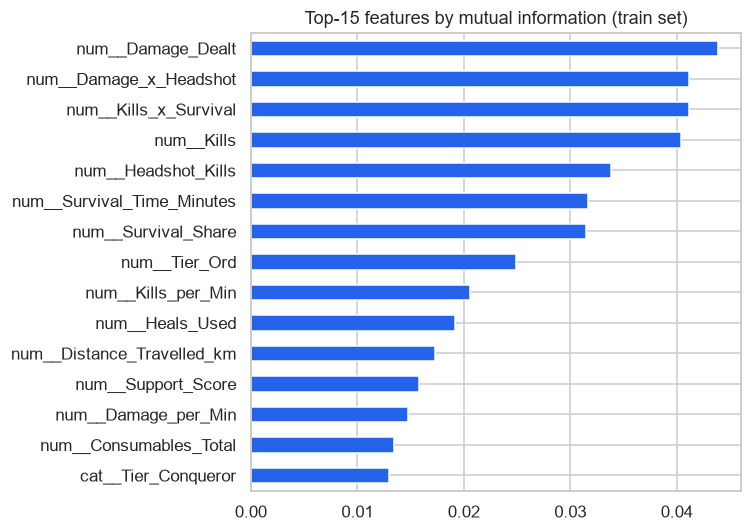

In [17]:
# 4.5 Scaling + encoding + feature selection are wrapped in a Pipeline (fitted on training data only)
preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
])

def make_pipe(model, k="all"):
    return Pipeline([("prep", preprocess),
                     ("select", SelectKBest(mutual_info_classif, k=k)),
                     ("model", model)])

# Feature selection view (mutual information on the training set)
Xt = preprocess.fit_transform(X_train)
names = preprocess.get_feature_names_out()
mi = pd.Series(mutual_info_classif(Xt, y_train, random_state=SEED), index=names).sort_values(ascending=False)
mi.head(15).sort_values().plot(kind="barh", figsize=(7, 5), color="#2563eb")
plt.title("Top-15 features by mutual information (train set)"); plt.tight_layout()
plt.savefig("figures/feature_mi.png"); plt.show()

# Part 5 – Model Implementation
Two comparative models:
* **Logistic Regression** – interpretable linear model.
* **Random Forest** – non-linear ensemble that can capture interactions.

The no-skill reference (ROC-AUC 0.5, PR-AUC = positive-class prevalence) is shown on the plots instead of a separate baseline model.

`class_weight="balanced"` handles the ~9.5 % positive class.

In [18]:
def precision_at_top(yte, p, frac=0.10):
    """Of the `frac` highest-scored players, what share really finished Top-10? (compare with prevalence)"""
    k = max(1, int(len(p) * frac)); top = np.argsort(-p)[:k]
    return float(np.asarray(yte)[top].mean())

def evaluate(model, Xte, yte, thr=0.5):
    p = model.predict_proba(Xte)[:, 1]
    pred = (p >= thr).astype(int)
    return {"ROC-AUC": roc_auc_score(yte, p), "PR-AUC": average_precision_score(yte, p),
            "Balanced Acc": balanced_accuracy_score(yte, pred), "Accuracy": accuracy_score(yte, pred),
            "Recall": recall_score(yte, pred), "F1": f1_score(yte, pred, zero_division=0)}

models = {
    "Logistic Regression": make_pipe(LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Random Forest": make_pipe(RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                                       n_jobs=-1, random_state=SEED)),
}
base_results = {}
for n, m in models.items():
    m.fit(X_train, y_train)
    base_results[n] = evaluate(m, X_test, y_test)
base_df = pd.DataFrame(base_results).T.round(3)
base_df

,ROC-AUC,PR-AUC,Balanced Acc,Accuracy,Recall,F1
Logistic Regression,0.772,0.251,0.690,0.701,0.677,0.296
Random Forest,0.750,0.228,0.551,0.891,0.134,0.187


In [19]:
# 5.1b Is there ANY learnable signal? ONE row per cluster (no copies -> no leakage possible)
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone
first = data.groupby("Group").head(1).index      # one representative per near-duplicate cluster
Xo, yo = X.loc[first], y.loc[first]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = {}
for n, m in models.items():
    auc = cross_val_score(clone(m), Xo, yo, cv=skf, scoring="roc_auc", n_jobs=-1)
    ap = cross_val_score(clone(m), Xo, yo, cv=skf, scoring="average_precision", n_jobs=-1)
    rows[n] = {"ROC-AUC (mean)": auc.mean(), "ROC-AUC (std)": auc.std(),
               "PR-AUC (mean)": ap.mean(), "No-skill PR-AUC": yo.mean()}
orig_signal = pd.DataFrame(rows).T.round(3)
print(f"{len(Xo)} one-row-per-cluster rows, Top-10 rate {yo.mean():.3f}")
orig_signal

10000 one-row-per-cluster rows, Top-10 rate 0.100


,ROC-AUC (mean),ROC-AUC (std),PR-AUC (mean),No-skill PR-AUC
Logistic Regression,0.773,0.015,0.303,0.1
Random Forest,0.750,0.018,0.269,0.1


**Reading 5.1b:** if ROC-AUC here is ~0.50 with a std of a few points, the features carry (almost) no information about Top-10 placement and the low scores are a property of the data, not a modelling mistake. State this explicitly in the report.

,ROC-AUC (random split),ROC-AUC (group split)
Logistic Regression,0.769,0.772
Random Forest,0.734,0.750


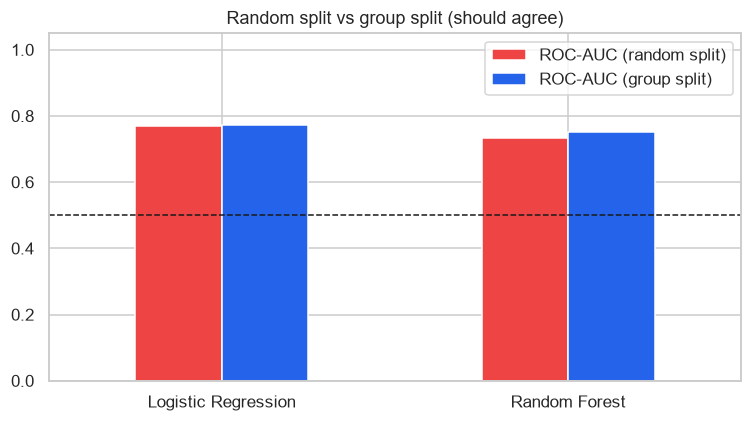

In [20]:
# 5.2 Split check: random stratified split vs group split. With independent rows the two should AGREE (no leakage)
leak = {}
for n in ["Logistic Regression", "Random Forest"]:
    m = make_pipe(models[n].named_steps["model"].__class__(**models[n].named_steps["model"].get_params()))
    m.fit(Xl_tr, yl_tr)
    leak[n] = {"ROC-AUC (random split)": roc_auc_score(yl_te, m.predict_proba(Xl_te)[:, 1]),
               "ROC-AUC (group split)": base_results[n]["ROC-AUC"]}
leak_df = pd.DataFrame(leak).T.round(3)
display(leak_df)
leak_df.plot(kind="bar", figsize=(7, 4), color=["#ef4444", "#2563eb"], rot=0)
plt.axhline(0.5, color="k", ls="--", lw=1); plt.ylim(0, 1.05); plt.title("Random split vs group split (should agree)")
plt.tight_layout(); plt.savefig("figures/leakage_effect.png"); plt.show()

# Part 6 – Hyper-parameter Tuning
`RandomizedSearchCV` with **GroupKFold** (so that near-copies never straddle a fold). The number of selected features `k` is tuned together with the model parameters. The scoring metric is **PR-AUC (average precision)** because the positive class is rare.

In [21]:
cv = GroupKFold(n_splits=5)
n_feat_total = len(names)

param_lr = {
    "select__k": [5, 10, 15, "all"],
    "model__C": np.logspace(-3, 2, 20),
    "model__penalty": ["l2"],
    "model__solver": ["lbfgs"],
}
param_rf = {
    "select__k": [5, 10, 15, "all"],
    "model__n_estimators": [200, 300, 500],
    "model__max_depth": [3, 4, 5, 6, 8],
    "model__min_samples_leaf": [20, 40, 80, 120],
    "model__max_features": ["sqrt", "log2", 0.3],
    "model__max_samples": [0.5, 0.7, None],
}

searches = {}
for name, pipe, grid, n_iter in [
    ("Logistic Regression", models["Logistic Regression"], param_lr, 30),
    ("Random Forest", models["Random Forest"], param_rf, 30),
]:
    rs = RandomizedSearchCV(pipe, grid, n_iter=n_iter, scoring="average_precision", cv=cv,
                            n_jobs=-1, random_state=SEED, return_train_score=True)
    rs.fit(X_train, y_train, groups=g_train)
    searches[name] = rs
    print(f"{name}: best CV PR-AUC = {rs.best_score_:.4f}\n   best params = {rs.best_params_}\n")

Logistic Regression: best CV PR-AUC = 0.3159
   best params = {'select__k': 15, 'model__solver': 'lbfgs', 'model__penalty': 'l2', 'model__C': np.float64(0.12742749857031335)}

Random Forest: best CV PR-AUC = 0.3075
   best params = {'select__k': 'all', 'model__n_estimators': 200, 'model__min_samples_leaf': 40, 'model__max_samples': 0.5, 'model__max_features': 'log2', 'model__max_depth': 6}



--- Logistic Regression: top 5 configurations ---


,rank_test_score,mean_test_score,std_test_score,mean_train_score,param_select__k,param_model__solver,param_model__penalty,param_model__C
24,1,0.3159,0.0153,0.3157,15,lbfgs,l2,0.1274
4,2,0.3157,0.0172,0.3153,15,lbfgs,l2,0.0113
7,3,0.3153,0.0155,0.3161,15,lbfgs,l2,29.7635
3,4,0.3152,0.0151,0.3238,all,lbfgs,l2,0.0695
2,5,0.3147,0.0159,0.3146,15,lbfgs,l2,0.0207


--- Random Forest: top 5 configurations ---


,rank_test_score,mean_test_score,std_test_score,mean_train_score,param_select__k,param_model__n_estimators,param_model__min_samples_leaf,param_model__max_samples,param_model__max_features,param_model__max_depth
22,1,0.3075,0.0254,0.3623,all,200,40,0.5,log2,6
14,2,0.3075,0.0260,0.3323,all,200,120,None,sqrt,4
8,3,0.3071,0.0237,0.3508,15,200,40,0.7,sqrt,5
11,4,0.3069,0.0271,0.3405,all,300,120,None,log2,8
27,5,0.3045,0.0278,0.3309,all,500,20,None,log2,3


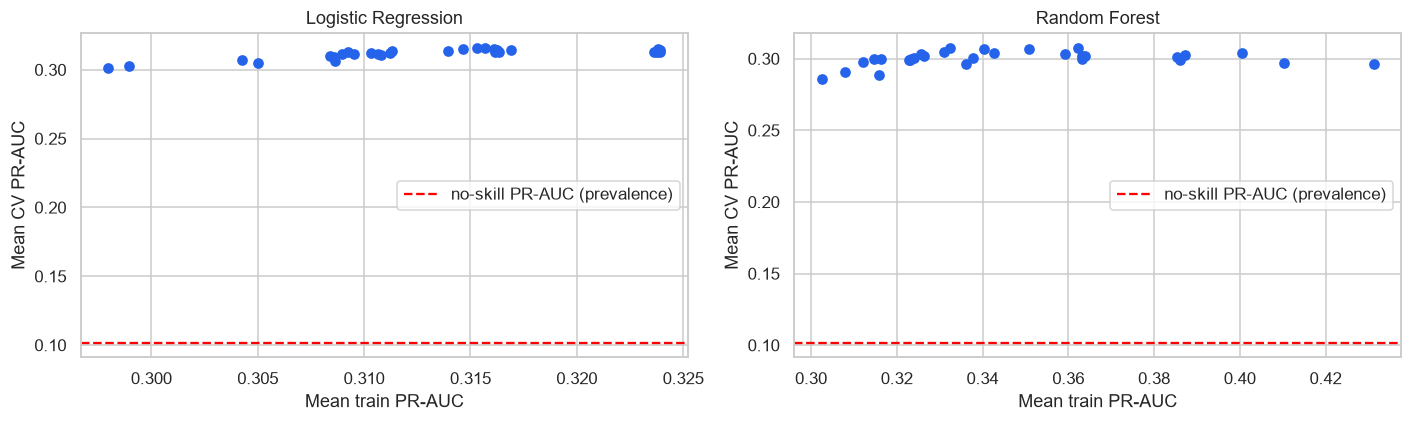

In [22]:
# Tuning evidence: top configurations and CV curves
for name, rs in searches.items():
    res = pd.DataFrame(rs.cv_results_).sort_values("rank_test_score")
    cols = ["rank_test_score", "mean_test_score", "std_test_score", "mean_train_score"] + \
           [c for c in res.columns if c.startswith("param_")]
    print(f"--- {name}: top 5 configurations ---")
    display(res[cols].head(5).round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for a, (name, rs) in zip(axes, searches.items()):
    res = pd.DataFrame(rs.cv_results_)
    a.scatter(res["mean_train_score"], res["mean_test_score"], c="#2563eb")
    a.axhline(y_train.mean(), color="red", ls="--", label="no-skill PR-AUC (prevalence)")
    a.set_xlabel("Mean train PR-AUC"); a.set_ylabel("Mean CV PR-AUC"); a.set_title(name); a.legend()
plt.tight_layout(); plt.savefig("figures/tuning_cv.png"); plt.show()

# Part 7 – Results and Evaluation

**Metric selection (justify in report):**
* *ROC-AUC* – threshold-independent ranking quality (0.5 = random).
* *PR-AUC* – more informative than ROC for the rare positive class; the random baseline equals the prevalence (~0.095).
* *Recall / Precision / F1* – trade-off between catching Top-10 players and false alarms.
* *Balanced accuracy* – accuracy corrected for imbalance (plain accuracy is misleading: always predicting "No" gives ~90 %).
* *Brier score* – quality of the predicted probabilities.

In [23]:
best = {n: rs.best_estimator_ for n, rs in searches.items()}
final = dict(best)

# Decision thresholds are chosen on TRAINING out-of-fold predictions (never on the test set)
from sklearn.model_selection import cross_val_predict
thr, thr_recall = {}, {}
TARGET_RECALL = 0.70
for n, m in best.items():
    oof = cross_val_predict(m, X_train, y_train, cv=cv, groups=g_train, method="predict_proba")[:, 1]
    p, r, t = precision_recall_curve(y_train, oof)
    f1s = 2*p*r/(p+r+1e-12)
    thr[n] = float(t[np.argmax(f1s[:-1])])                       # F1-optimal
    ok = np.where(r[:-1] >= TARGET_RECALL)[0]                    # highest threshold that still reaches the recall target
    thr_recall[n] = float(t[ok[-1]]) if len(ok) else thr[n]
print("F1-optimal thresholds :", {k: round(v, 3) for k, v in thr.items()})
print(f"Recall>={TARGET_RECALL:.0%} thresholds:", {k: round(v, 3) for k, v in thr_recall.items()})

rows = {}
for n, m in final.items():
    rows[n + " (default 0.5)"] = evaluate(m, X_test, y_test)
    rows[n + " (F1 thr)"] = evaluate(m, X_test, y_test, thr[n])
    rows[n + f" (recall~{TARGET_RECALL:.0%} thr)"] = evaluate(m, X_test, y_test, thr_recall[n])
comparison = pd.DataFrame(rows).T.round(3)
print("Test-set prevalence (no-skill PR-AUC / precision):", round(y_test.mean(), 3))
comparison


F1-optimal thresholds : {'Logistic Regression': 0.662, 'Random Forest': 0.629}
Recall>=70% thresholds: {'Logistic Regression': 0.518, 'Random Forest': 0.514}
Test-set prevalence (no-skill PR-AUC / precision): 0.093


,ROC-AUC,PR-AUC,Balanced Acc,Accuracy,Recall,F1
Logistic Regression (default 0.5),0.774,0.256,0.692,0.709,0.672,0.300
Logistic Regression (F1 thr),0.774,0.256,0.646,0.834,0.414,0.317
Logistic Regression (recall~70% thr),0.774,0.256,0.692,0.730,0.645,0.307
Random Forest (default 0.5),0.773,0.258,0.701,0.702,0.699,0.304
Random Forest (F1 thr),0.773,0.258,0.670,0.818,0.489,0.333
Random Forest (recall~70% thr),0.773,0.258,0.697,0.716,0.672,0.306


In [24]:
# 7.0b Same evaluation using one row per group (every row is its own group here, so this equals the main test result)
te_first = ~data.iloc[te_idx]["Group"].duplicated().values
rows = {n: evaluate(m, X_test[te_first], y_test[te_first]) for n, m in final.items()}
print(f"One-row-per-cluster test rows: {te_first.sum()} | Top-10 rate {y_test[te_first].mean():.3f}")
pd.DataFrame(rows).T.round(3)

One-row-per-cluster test rows: 2000 | Top-10 rate 0.093


,ROC-AUC,PR-AUC,Balanced Acc,Accuracy,Recall,F1
Logistic Regression,0.774,0.256,0.692,0.709,0.672,0.300
Random Forest,0.773,0.258,0.701,0.702,0.699,0.304


In [25]:
# 7.0c Sensitivity to the target definition: Top-10 vs Top-25 vs Top-50 (same tuned models, same group split)
sens = []
for cut in [10, 25, 50]:
    yc = (data["Match_Rank"] <= cut).astype(int)
    for n, m in final.items():
        mm = clone(m).fit(X_train, yc.iloc[tr_idx])
        pc = mm.predict_proba(X_test)[:, 1]
        sens.append({"Target": f"Top-{cut}", "Model": n, "Prevalence": yc.iloc[te_idx].mean(),
                     "ROC-AUC": roc_auc_score(yc.iloc[te_idx], pc),
                     "PR-AUC": average_precision_score(yc.iloc[te_idx], pc),
                     "Precision@top10%": precision_at_top(yc.iloc[te_idx], pc)})
pd.DataFrame(sens).round(3)

,Target,Model,Prevalence,ROC-AUC,PR-AUC,Precision@top10%
0,Top-10,Logistic Regression,0.093,0.775,0.258,0.310
1,Top-10,Random Forest,0.093,0.773,0.258,0.300
2,Top-25,Logistic Regression,0.235,0.740,0.471,0.565
3,Top-25,Random Forest,0.235,0.738,0.463,0.565
4,Top-50,Logistic Regression,0.476,0.718,0.689,0.800
5,Top-50,Random Forest,0.476,0.714,0.684,0.800


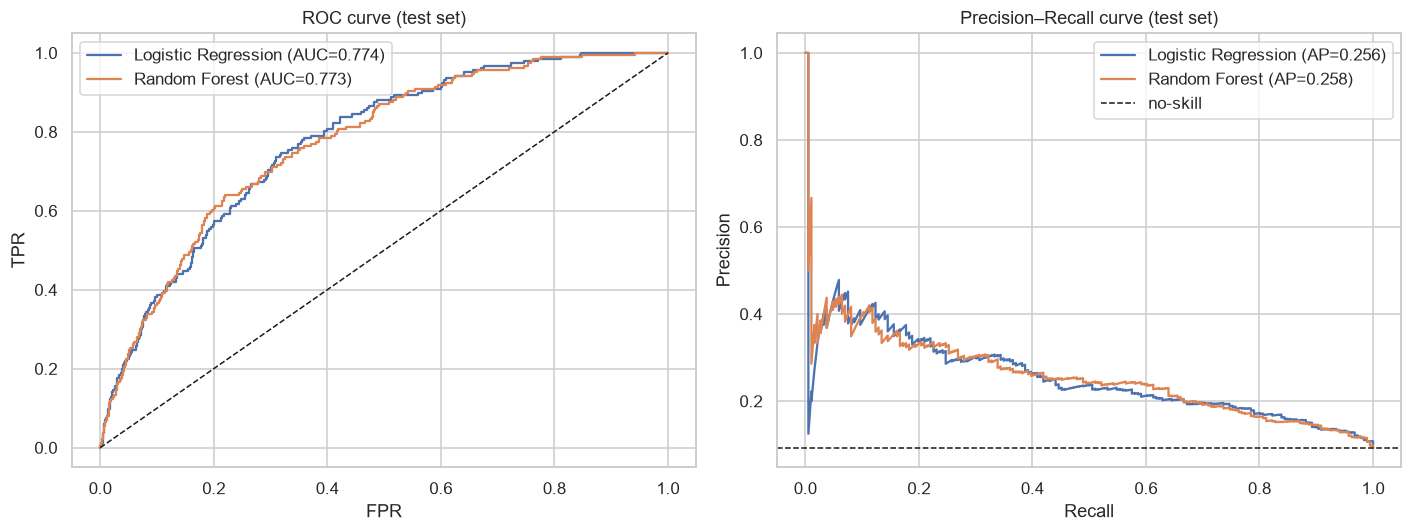

In [26]:
# 7.1 ROC and PR curves
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for n, m in final.items():
    p = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p); ax[0].plot(fpr, tpr, label=f"{n} (AUC={roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p); ax[1].plot(rc, pr, label=f"{n} (AP={average_precision_score(y_test, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set_title("ROC curve (test set)"); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR"); ax[0].legend()
ax[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label="no-skill"); ax[1].set_title("Precision–Recall curve (test set)")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].legend()
plt.tight_layout(); plt.savefig("figures/roc_pr.png"); plt.show()

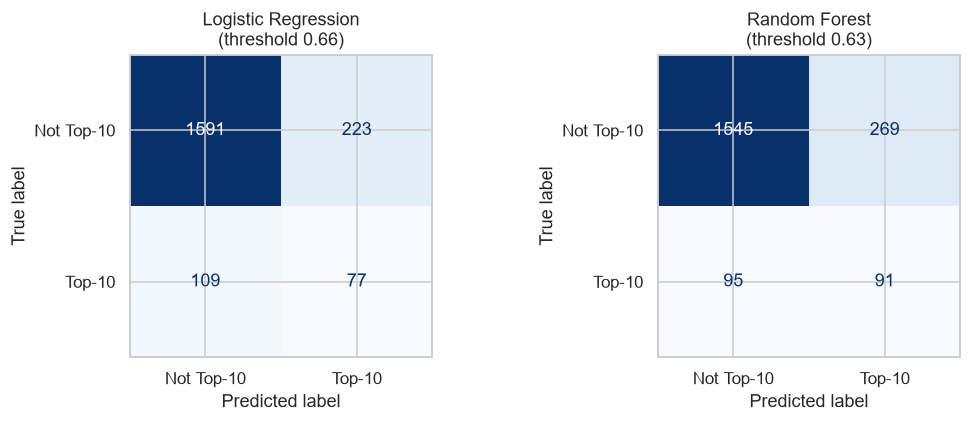

In [27]:
# 7.2 Confusion matrices (tuned models, tuned threshold)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for a, n in zip(axes, best):
    pred = (best[n].predict_proba(X_test)[:, 1] >= thr[n]).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Not Top-10", "Top-10"]).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(f"{n}\n(threshold {thr[n]:.2f})")
plt.tight_layout(); plt.savefig("figures/confusion.png"); plt.show()

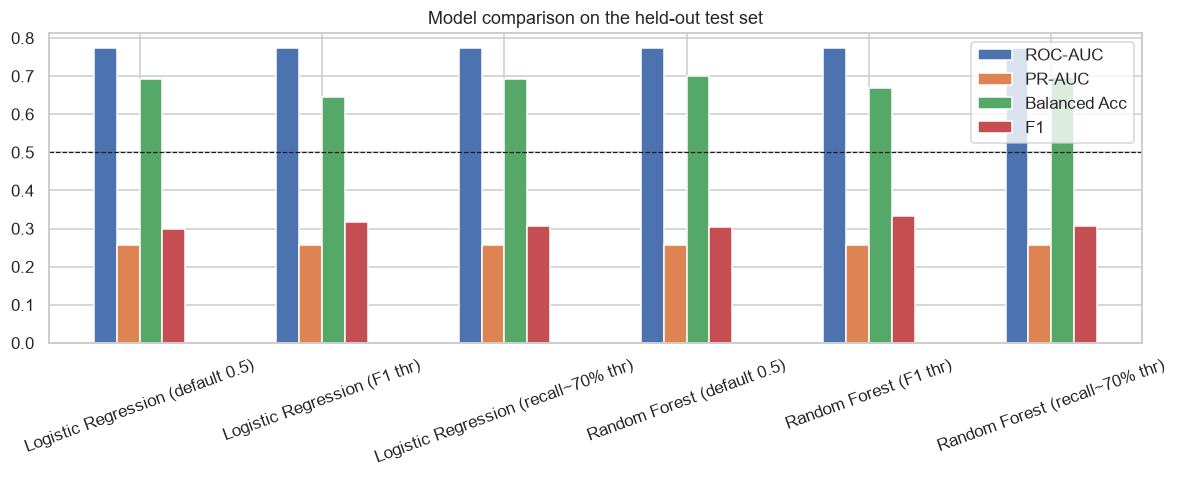

In [28]:
# 7.3 Metric comparison bar chart
comparison[["ROC-AUC", "PR-AUC", "Balanced Acc", "F1"]].plot(kind="bar", figsize=(11, 4.5), rot=20)
plt.axhline(0.5, color="k", ls="--", lw=.8); plt.title("Model comparison on the held-out test set")
plt.tight_layout(); plt.savefig("figures/model_comparison.png"); plt.show()

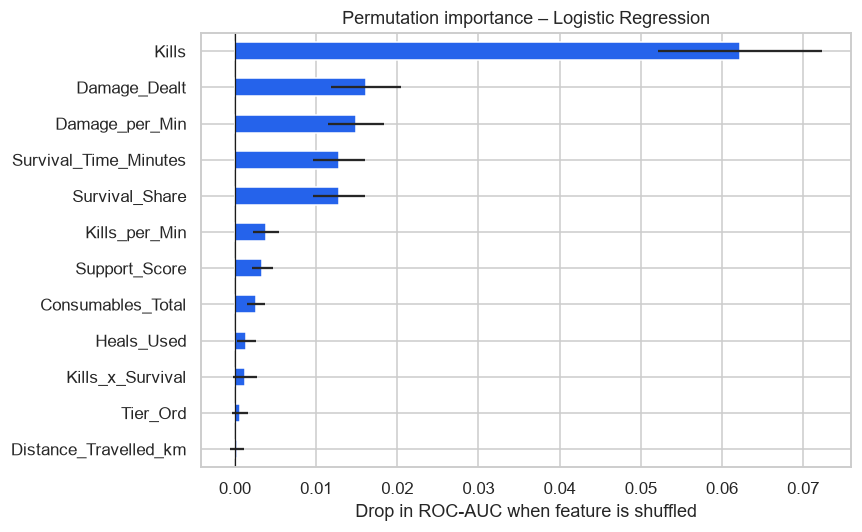

In [29]:
# 7.4 Interpretation: permutation importance of the best model on the test set
best_name = max(best, key=lambda n: roc_auc_score(y_test, best[n].predict_proba(X_test)[:, 1]))
pi = permutation_importance(best[best_name], X_test, y_test, scoring="roc_auc", n_repeats=15,
                            random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
imp.tail(12).plot(kind="barh", xerr=pd.Series(pi.importances_std, index=X_test.columns)[imp.tail(12).index],
                  figsize=(8, 5), color="#2563eb")
plt.axvline(0, color="k", lw=.8); plt.title(f"Permutation importance – {best_name}")
plt.xlabel("Drop in ROC-AUC when feature is shuffled"); plt.tight_layout()
plt.savefig("figures/perm_importance.png"); plt.show()

In [30]:
# 7.5 Is the result better than chance? Bootstrap CI of ROC-AUC on the test set
# Rows in a cluster are near-copies, so resampling them as independent rows makes the CI far too narrow.
# We therefore bootstrap over GROUPS (a record + its copies are resampled together).
rng = np.random.default_rng(SEED)
p_best = best[best_name].predict_proba(X_test)[:, 1]
yt = y_test.values
g_test = groups[te_idx]
ug = np.unique(g_test)
members = {g: np.where(g_test == g)[0] for g in ug}
aucs = []
for _ in range(1000):
    pick = rng.choice(ug, len(ug), replace=True)
    i = np.concatenate([members[g] for g in pick])
    if yt[i].min() != yt[i].max():
        aucs.append(roc_auc_score(yt[i], p_best[i]))
lo, hi = np.percentile(aucs, [2.5, 97.5])
print(f"{best_name}: test ROC-AUC = {roc_auc_score(yt, p_best):.3f}  (95% group-bootstrap CI {lo:.3f} - {hi:.3f})")
print("If the interval contains 0.5, the model is not statistically better than random guessing.")

Logistic Regression: test ROC-AUC = 0.774  (95% group-bootstrap CI 0.741 - 0.805)
If the interval contains 0.5, the model is not statistically better than random guessing.


**Interpretation and critical analysis (write in your own words using the numbers above):**
1. Compare the two tuned models on ROC-AUC, PR-AUC, precision@top-10 % and F1. State clearly whether they beat the no-skill reference (ROC-AUC 0.5; PR-AUC equal to the ~10 % prevalence) and give the group-bootstrap interval from 7.5.
2. Explain 5.2: random and group splits give similar scores because the rows are independent, so there is no leakage in this dataset (contrast with the earlier expanded file, where a random split gave ~0.98 and the honest split ~0.5).
3. Link results to the EDA: moderate correlations (damage, kills, survival time) explain moderate, not perfect, performance. The remaining error comes from the noise built into the simulation.
4. Discuss the threshold trade-off (higher recall → more false alarms) and what it means for coaches, and why accuracy is misleading for a 10 % positive class.
5. Limitations: the data are simulated, so the results show the pipeline recovers assumed relationships, not real-player predictability; single match per row; no squad/time context; no Nepal-specific real data.
6. The bootstrap in 7.5 resamples whole groups; here each row is its own group, so it equals a standard bootstrap.

# Part 8 – Intelligent System Architecture
A trained model alone is not an intelligent system. The proposed system wraps the model in the **five elements** of an intelligent system (adapt the naming to the definitions used in your lecture slides):

| # | Element | In this system |
|---|---|---|
| 1 | **Perception / Data acquisition** | Collects match logs and player profiles (CSV/API/game telemetry), validates schema and ranges |
| 2 | **Knowledge & Learning** | Feature store + trained Logistic Regression / Random Forest pipeline, periodic re-training |
| 3 | **Reasoning / Decision-making** | Probability of Top-10, tuned threshold, explanations (feature importance), rule checks |
| 4 | **Action / Interaction** | Coaching dashboard/API: placement-risk score, improvement suggestions for players and coaches |
| 5 | **Feedback & Adaptation** | Monitoring (drift, accuracy), human feedback from coaches, re-training loop |

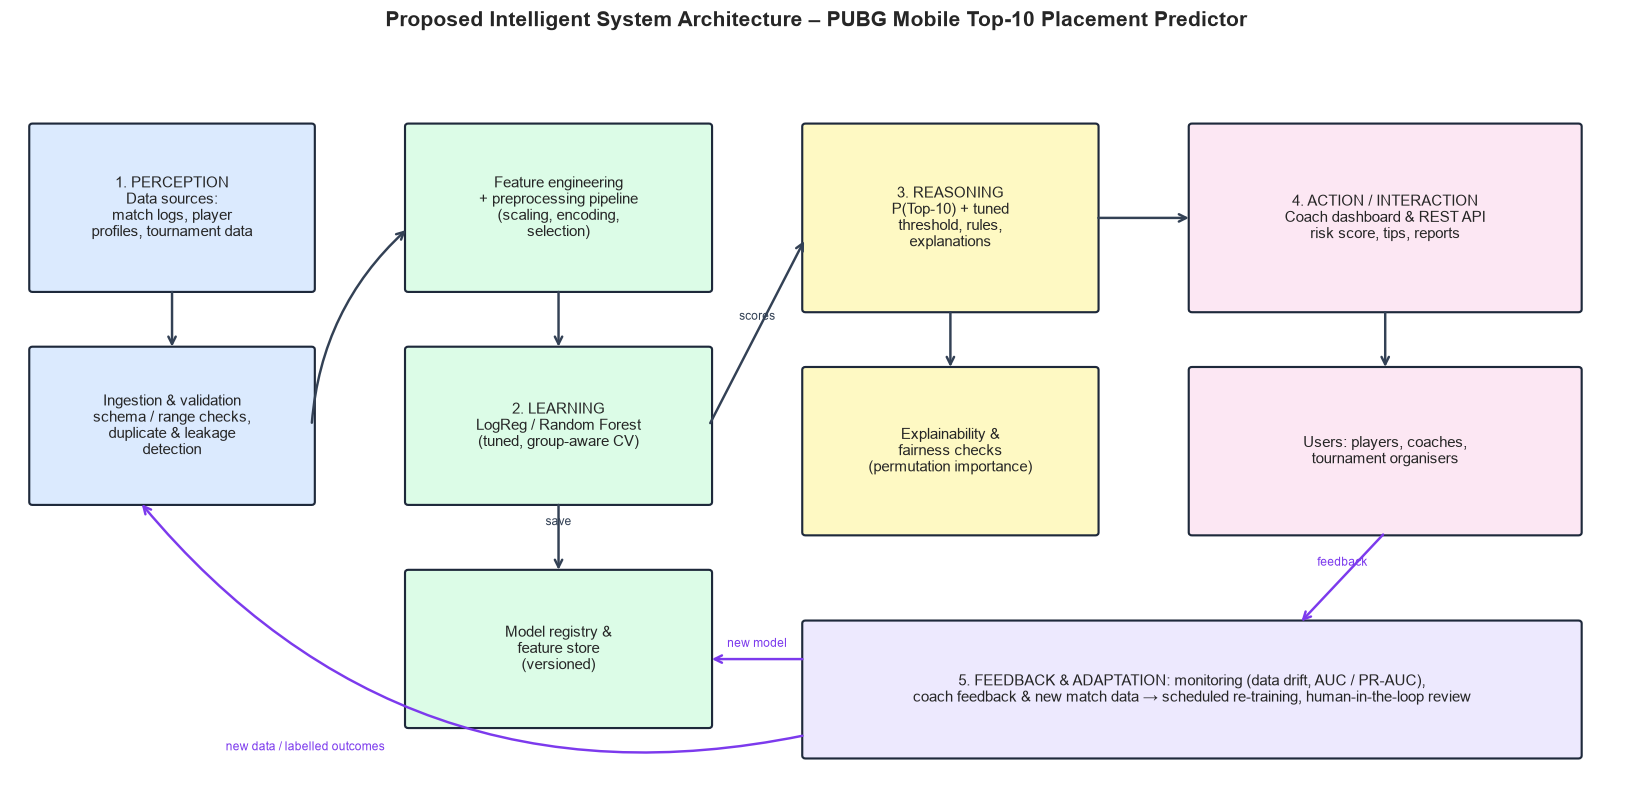

In [31]:
def box(ax, x, y, w, h, text, fc):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.03", fc=fc, ec="#1e293b", lw=1.4))
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=9.5)

def arrow(ax, a, b, txt="", style="->", color="#334155", rad=0.0):
    ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle=style, lw=1.6, color=color,
                                                    connectionstyle=f"arc3,rad={rad}"))
    if txt:
        ax.text((a[0]+b[0])/2, (a[1]+b[1])/2 + 0.12, txt, ha="center", fontsize=8, color=color)

fig, ax = plt.subplots(figsize=(15, 7.5)); ax.set_xlim(0, 15); ax.set_ylim(0, 7.5); ax.axis("off")
ax.set_title("Proposed Intelligent System Architecture – PUBG Mobile Top-10 Placement Predictor",
             fontsize=14, fontweight="bold")
c1, c2, c3, c4, c5 = "#dbeafe", "#dcfce7", "#fef9c3", "#fce7f3", "#ede9fe"
# 1 Perception
box(ax, 0.2, 5.0, 2.6, 1.6, "1. PERCEPTION\nData sources:\nmatch logs, player\nprofiles, tournament data", c1)
box(ax, 0.2, 2.9, 2.6, 1.5, "Ingestion & validation\nschema / range checks,\nduplicate & leakage\ndetection", c1)
# 2 Learning
box(ax, 3.7, 5.0, 2.8, 1.6, "Feature engineering\n+ preprocessing pipeline\n(scaling, encoding,\nselection)", c2)
box(ax, 3.7, 2.9, 2.8, 1.5, "2. LEARNING\nLogReg / Random Forest\n(tuned, group-aware CV)", c2)
box(ax, 3.7, 0.7, 2.8, 1.5, "Model registry &\nfeature store\n(versioned)", c2)
# 3 Reasoning
box(ax, 7.4, 4.8, 2.7, 1.8, "3. REASONING\nP(Top-10) + tuned\nthreshold, rules,\nexplanations", c3)
box(ax, 7.4, 2.6, 2.7, 1.6, "Explainability &\nfairness checks\n(permutation importance)", c3)
# 4 Action
box(ax, 11.0, 4.8, 3.6, 1.8, "4. ACTION / INTERACTION\nCoach dashboard & REST API\nrisk score, tips, reports", c4)
box(ax, 11.0, 2.6, 3.6, 1.6, "Users: players, coaches,\ntournament organisers", c4)
# 5 Feedback
box(ax, 7.4, 0.4, 7.2, 1.3, "5. FEEDBACK & ADAPTATION: monitoring (data drift, AUC / PR-AUC),\ncoach feedback & new match data → scheduled re-training, human-in-the-loop review", c5)

arrow(ax, (1.5, 5.0), (1.5, 4.4)); arrow(ax, (2.8, 3.65), (3.7, 5.6), rad=-0.2)
arrow(ax, (5.1, 5.0), (5.1, 4.4)); arrow(ax, (6.5, 3.65), (7.4, 5.5), "scores")
arrow(ax, (5.1, 2.9), (5.1, 2.2), "save"); arrow(ax, (10.1, 5.7), (11.0, 5.7))
arrow(ax, (8.75, 4.8), (8.75, 4.2)); arrow(ax, (12.8, 4.8), (12.8, 4.2))
arrow(ax, (12.8, 2.6), (12.0, 1.7), "feedback", color="#7c3aed")
arrow(ax, (7.4, 1.35), (6.5, 1.35), "new model", color="#7c3aed")
arrow(ax, (7.4, 0.6), (1.2, 2.9), color="#7c3aed", rad=-0.3)
ax.text(2.0, 0.45, "new data / labelled outcomes", fontsize=8, color="#7c3aed")
plt.tight_layout(); plt.savefig("figures/system_architecture.png", bbox_inches="tight"); plt.show()

In [32]:
# Prototype of the deployable "reasoning + action" layer: saved pipeline + prediction function
final_model = best[best_name]
final_thr = thr[best_name]
joblib.dump({"model": final_model, "threshold": final_thr, "features": list(X.columns)}, "pubg_top10_model.joblib")

def advise(player: dict) -> dict:
    """Takes raw match stats, returns probability, decision and a simple explanation."""
    row = add_features(pd.DataFrame([player]))
    prob = float(final_model.predict_proba(row[X.columns])[:, 1][0])
    tips = []
    if player["Survival_Time_Minutes"] < 12: tips.append("Survive longer: rotate earlier and avoid early fights.")
    if player["Heals_Used"] + player["Boosts_Used"] < 4: tips.append("Use more heals/boosts to stay alive in late circles.")
    if player["Headshot_Percentage"] < 20: tips.append("Practise recoil control to raise headshot rate.")
    return {"P(Top10)": round(prob, 3), "Predicted": "Top-10" if prob >= final_thr else "Outside Top-10",
            "Suggestions": tips or ["Keep current playstyle."]}

example = data.iloc[0][num_cols + cat_cols].to_dict()
example = {k: (v.item() if hasattr(v, "item") else v) for k, v in example.items()}
advise(example)

{'P(Top10)': 0.495,
 'Predicted': 'Outside Top-10',
 'Suggestions': ['Keep current playstyle.']}

# Part 9 – Ethical Governance
Discuss each of these in the report with references (e.g. EU Ethics Guidelines for Trustworthy AI, IEEE Ethically Aligned Design, Nepal's Privacy Act 2075 / Individual Privacy Act, game publisher data policies):

| Principle | Risk in this system | Mitigation |
|---|---|---|
| **Fairness & bias** | Model may disadvantage certain maps, tiers or play styles; training data not Nepal-specific | Subgroup performance audits (by tier/map), representative Nepali data collection, avoid using protected attributes |
| **Privacy** | Player IDs and behavioural telemetry are personal data | Consent, anonymisation / pseudonymisation, data minimisation, retention limits, secure storage |
| **Transparency & explainability** | Players may not understand why they were scored low | Show feature importance/explanations, publish model card and known limitations |
| **Accountability** | Wrong predictions could affect scouting or team selection | Human-in-the-loop decisions, audit logs, named owner, appeals process |
| **Data quality / synthetic data** | Simulated data: relationships are assumptions, so scores show the pipeline works but do not describe real players (shown in Part 5.2) | Document provenance, group-aware validation, prefer real match data |
| **Responsible use & wellbeing** | Over-reliance may cause pressure, cheating allegations or addictive play | Use as advisory only, never as sole basis for bans/selection, promote healthy-gaming guidance |
| **Security** | Tampering with stats or model | Access control, input validation, monitoring for drift/adversarial inputs |

# Part 10 – Conclusion (summary notes for the report)
Fill in using your final numbers:
* **Key findings:** Top-10 finishes are rare (~10 %); in the simulated data damage, kills and survival time are the most informative features; no leakage was found in this dataset.
* **Objectives achievement:** data explored/cleaned ✔, features engineered ✔, two models implemented ✔, tuned with cross-validation ✔, evaluated with imbalance-aware metrics ✔, architecture + ethics proposed ✔.
* **Model findings:** report tuned Logistic Regression vs Random Forest (ROC-AUC, PR-AUC, precision@top-10 %, F1) against the no-skill reference.
* **Limitations:** simulated data with assumed relationships, single-match snapshot, no squad/time context, no real Nepali telemetry.
* **Future work:** validate on real PUBG Mobile / Nepal tournament telemetry, add squad/time features, try gradient boosting and calibration, deploy the dashboard/API and monitor drift.

# Appendix
* Figures saved in `./figures/`; trained model in `pubg_top10_model.joblib`.
* Add the shareable link to this notebook (Colab/GitHub) in the report's Appendix section.
* If you used any AI tool, cite it, interpret its output and include prompt screenshots as required by the brief.